In [1]:
from utils import get_hdf5_files, get_filename, get_continuous_behaviors, get_discrete_states, get_eigenworms, get_kymograph, get_neuronal_traces, get_variance_explained

import os
import math
from matplotlib import pyplot as plt
from matplotlib import colors
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA

In [2]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
hdf5files = get_hdf5_files(path)
filenames = [get_filename(file) for file in hdf5files]
continuous_behaviors = [get_continuous_behaviors(file) for file in hdf5files]
discrete_states = [get_discrete_states(file) for file in hdf5files]
eigenworms = [get_eigenworms(file) for file in hdf5files]
kymographs = [get_kymograph(file) for file in hdf5files]
traces = [get_neuronal_traces(file) for file in hdf5files]

# preprocessing

In [3]:
for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

# manifold

In [4]:
worm_id = 33

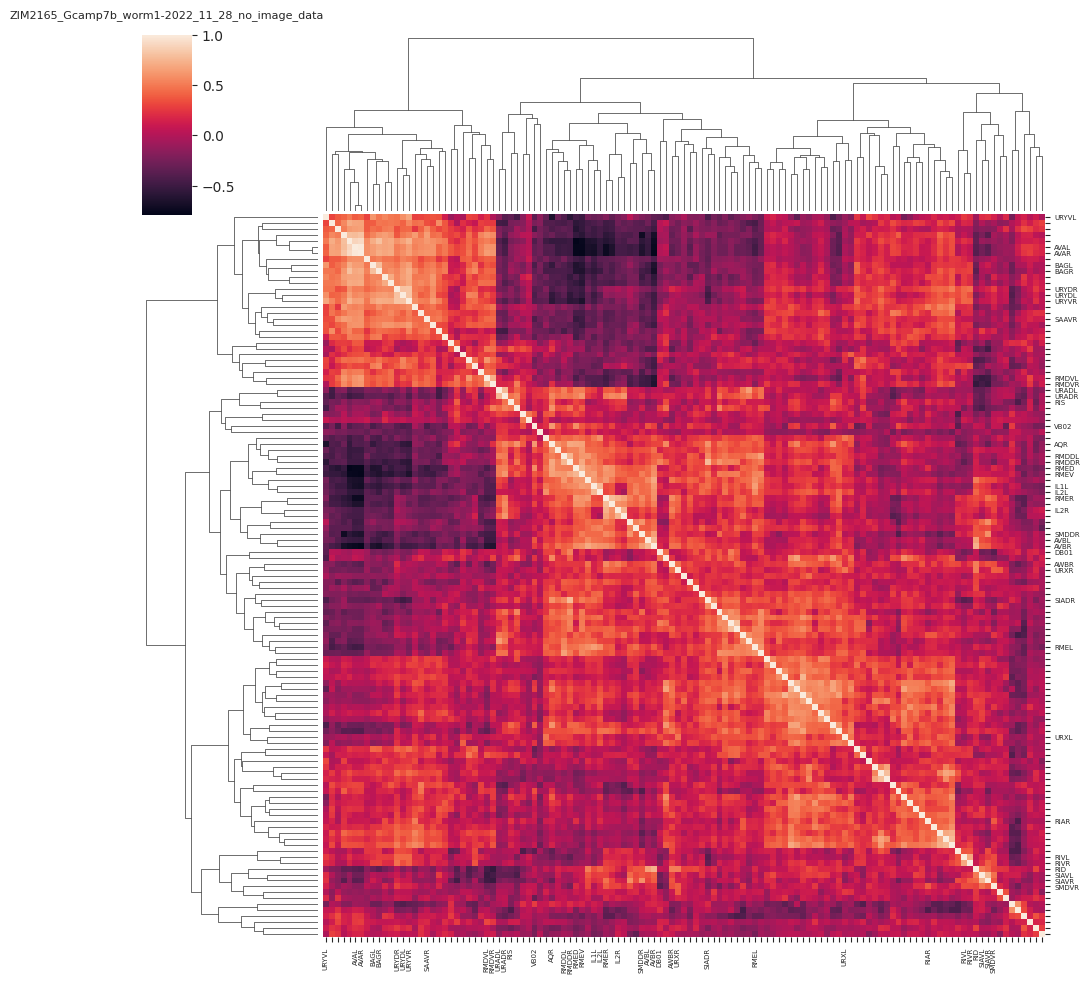

In [5]:
correlation = traces[worm_id].corr()
heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(filenames[worm_id], fontsize=8, y=1.05)
pass

0.4292540674885418 0.6894073565366023


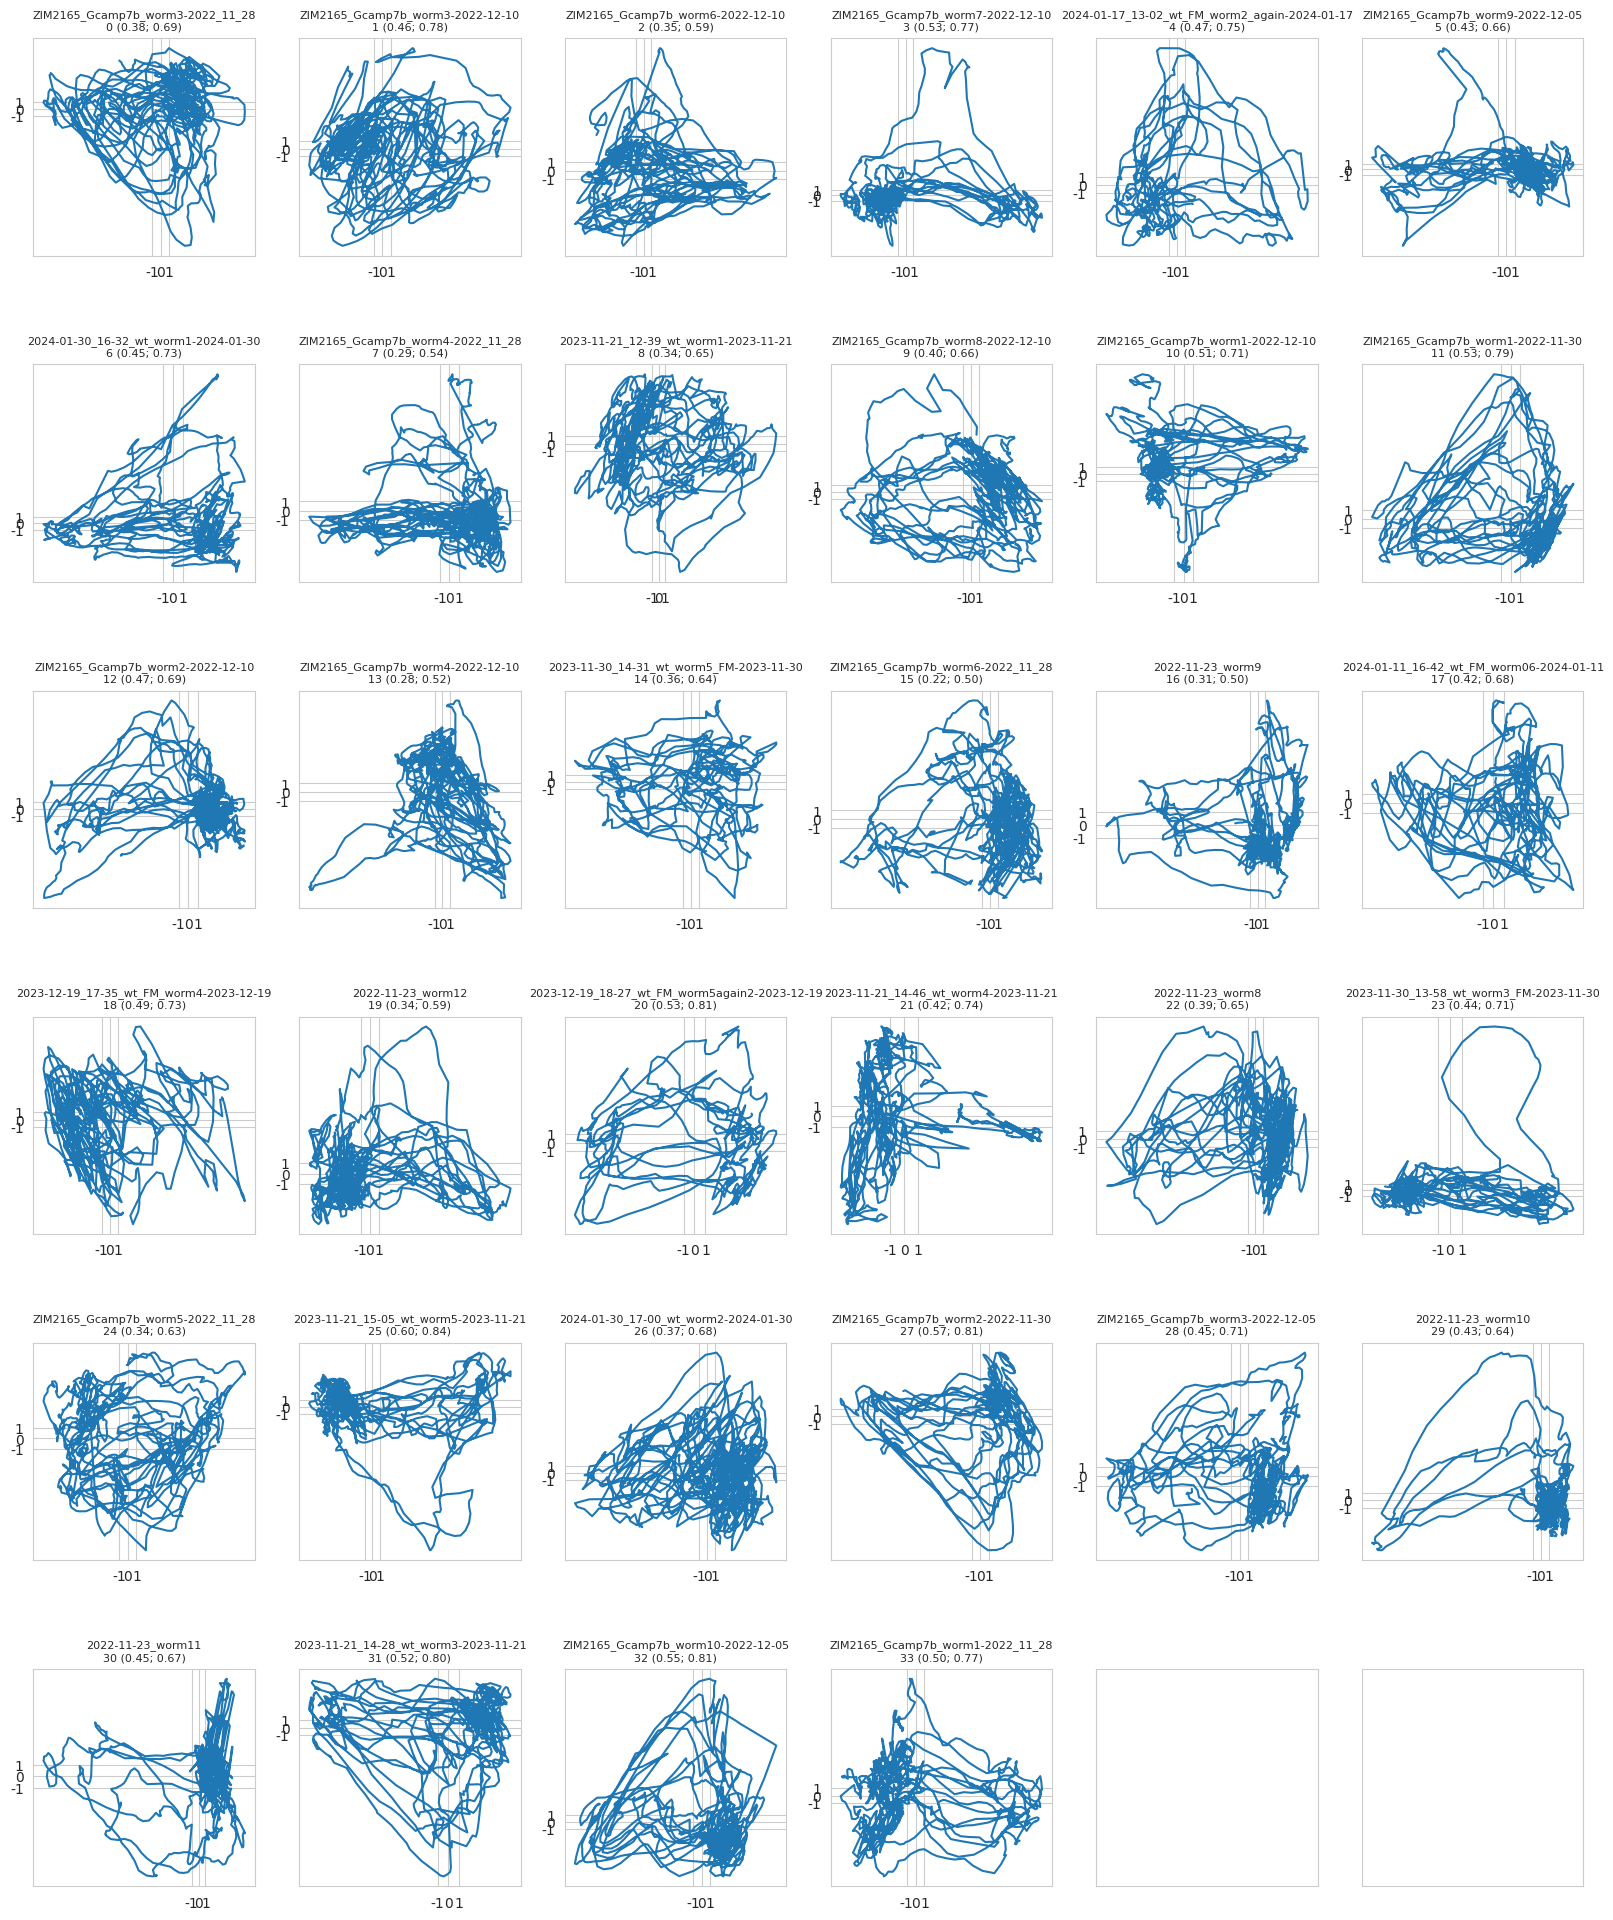

In [6]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

modes_manifold = list()
traces_manifold = list()
cca_man_loadings = list()
man_vars_expl_rs = list()  # variance explained with respect to the reconstructed PCA data
man_vars_expl = list()
for trace, ds in zip(traces, discrete_states):

	pca = PCA(n_components=5)
	trace_reduced_pca = pca.fit_transform(trace.values)
	trace_reconstructed_pca = pca.inverse_transform(trace_reduced_pca)

	cca = CCA(n_components=2, scale=True)
	trace_reduced_cca, ds_reduced_cca = cca.fit_transform(trace_reconstructed_pca, ds[selection].values)
	trace_reconstructed_cca, ds_reconstructed_cca = cca.inverse_transform(trace_reduced_cca, ds_reduced_cca)

	modes_manifold.append(pd.DataFrame(data=trace_reduced_cca, columns=[f'CC{n+1}' for n in range(2)]))
	traces_manifold.append(pd.DataFrame(data=trace_reconstructed_cca, columns=trace.columns))

	cca_man_loadings.append((cca.x_loadings_, cca.y_loadings_))

	X_var_ratio_rs = get_variance_explained(trace_reconstructed_pca, trace_reconstructed_cca)
	X_var_ratio = get_variance_explained(trace, trace_reconstructed_cca)
	man_vars_expl_rs.append(X_var_ratio_rs)
	man_vars_expl.append(X_var_ratio)


n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 24))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

scale = [-1, 0, 1]
for i, mode in enumerate(modes_manifold):
	axes[i // dim, i % dim].plot(mode['CC1'], mode['CC2'])
	axes[i // dim, i % dim].set_xticks(scale)
	axes[i // dim, i % dim].set_xticklabels(scale)
	axes[i // dim, i % dim].set_yticks(scale)
	axes[i // dim, i % dim].set_yticklabels(scale)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n{i} ({man_vars_expl[i]:.2f}; {man_vars_expl_rs[i]:.2f})', fontsize=8)

plt.subplots_adjust(hspace=0.5)
print(np.mean(np.array(man_vars_expl)), np.mean(np.array(man_vars_expl_rs)))

In [7]:
discrete_state_indices = np.argsort(cca_man_loadings[worm_id][1][:, 0])
trace_indices = np.argsort(cca_man_loadings[worm_id][0][:, 0])[::-1]

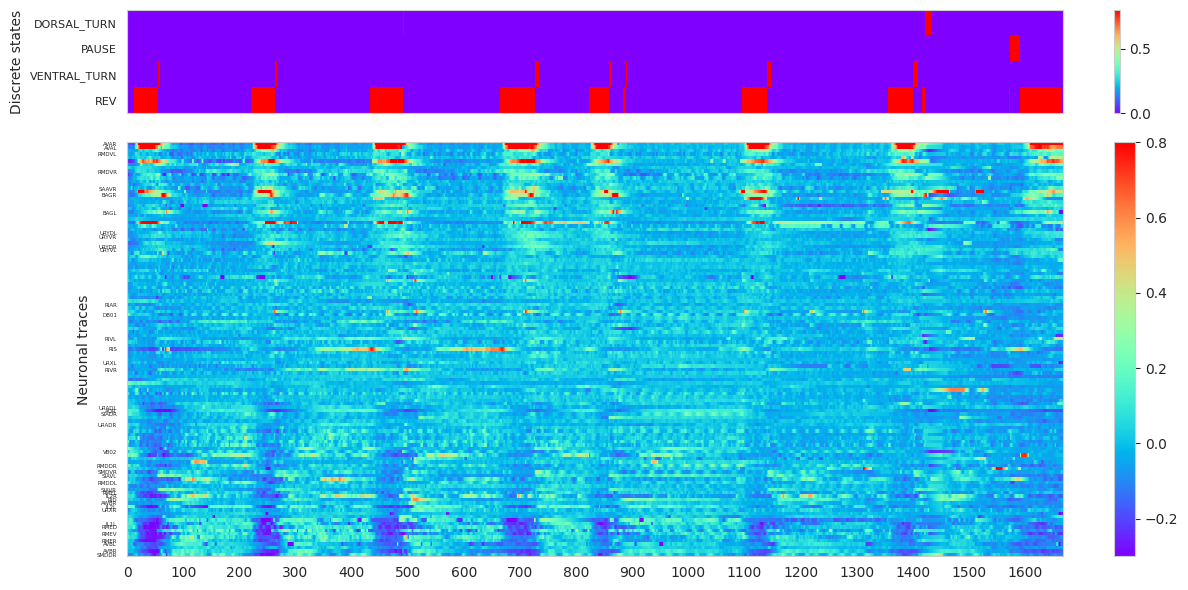

In [8]:
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 4]})

im_top = ax_top.imshow(np.clip(discrete_states[worm_id][selection].values.T[discrete_state_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_top.set_ylabel("Discrete states")
ax_top.set_yticks(np.arange(len(discrete_states[worm_id][selection].values.T[discrete_state_indices])))
ax_top.set_yticklabels(discrete_states[worm_id][selection].columns[discrete_state_indices], fontsize=8)
ax_top.set_xticks(np.arange(0, len(discrete_states[worm_id][selection].values), 100))
fig.colorbar(im_top, ax=ax_top, orientation='vertical', fraction=0.05)
ax_top.grid(False)

im_bottom = ax_bottom.imshow(np.clip(traces[worm_id].values.T[trace_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_bottom.set_ylabel("Neuronal traces")
ax_bottom.set_yticks(np.arange(len(traces[worm_id].values.T)))
ax_bottom.set_yticklabels(traces[worm_id].columns[trace_indices], fontsize=4)
ax_bottom.set_xticks(np.arange(0, len(traces[worm_id].values), 100))
fig.colorbar(im_bottom, ax=ax_bottom, orientation='vertical', fraction=0.05)
ax_bottom.grid(False)

plt.tight_layout()
# plt.savefig('./out/traces.png', dpi=300)
plt.show()

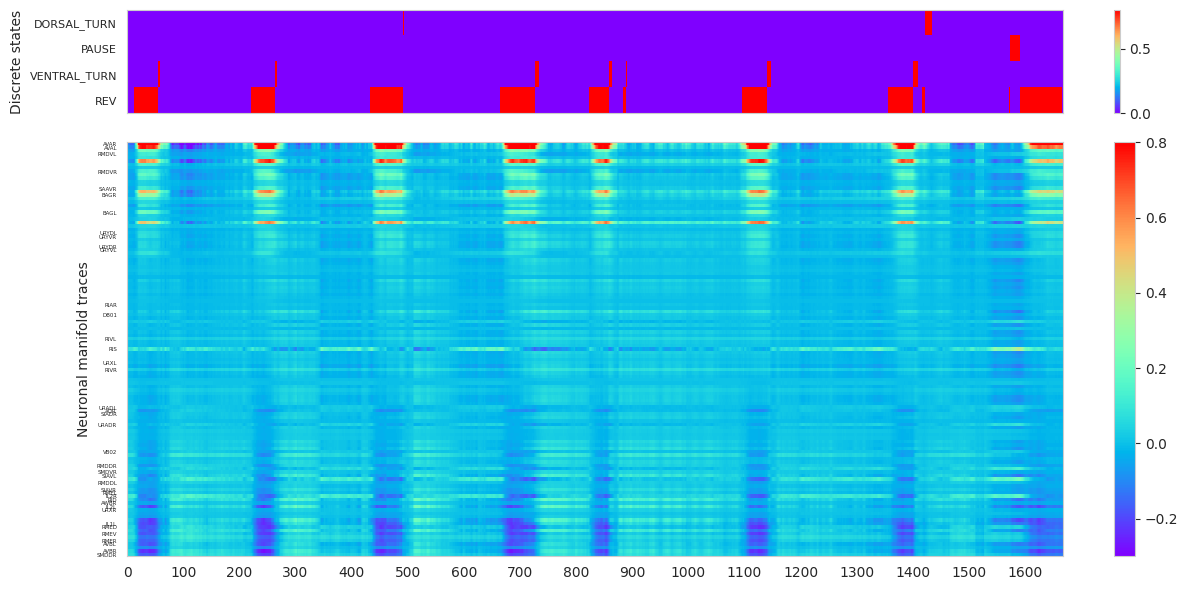

In [9]:
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 4]})

im_top = ax_top.imshow(np.clip(discrete_states[worm_id][selection].values.T[discrete_state_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_top.set_ylabel("Discrete states")
ax_top.set_yticks(np.arange(len(discrete_states[worm_id][selection].values.T[discrete_state_indices])))
ax_top.set_yticklabels(discrete_states[worm_id][selection].columns[discrete_state_indices], fontsize=8)
ax_top.set_xticks(np.arange(0, len(discrete_states[worm_id][selection].values), 100))
fig.colorbar(im_top, ax=ax_top, orientation='vertical', fraction=0.05)
ax_top.grid(False)

im_bottom = ax_bottom.imshow(np.clip(traces_manifold[worm_id].values.T[trace_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_bottom.set_ylabel("Neuronal manifold traces")
ax_bottom.set_yticks(np.arange(len(traces_manifold[worm_id].values.T)))
ax_bottom.set_yticklabels(traces_manifold[worm_id].columns[trace_indices], fontsize=4)
ax_bottom.set_xticks(np.arange(0, len(traces_manifold[worm_id].values), 100))
fig.colorbar(im_bottom, ax=ax_bottom, orientation='vertical', fraction=0.05)
ax_bottom.grid(False)

plt.tight_layout()
# plt.savefig('./out/traces_manifold.png', dpi=300)
plt.show()

# concrete behavior

In [10]:
traces_residual = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces, traces_manifold)]

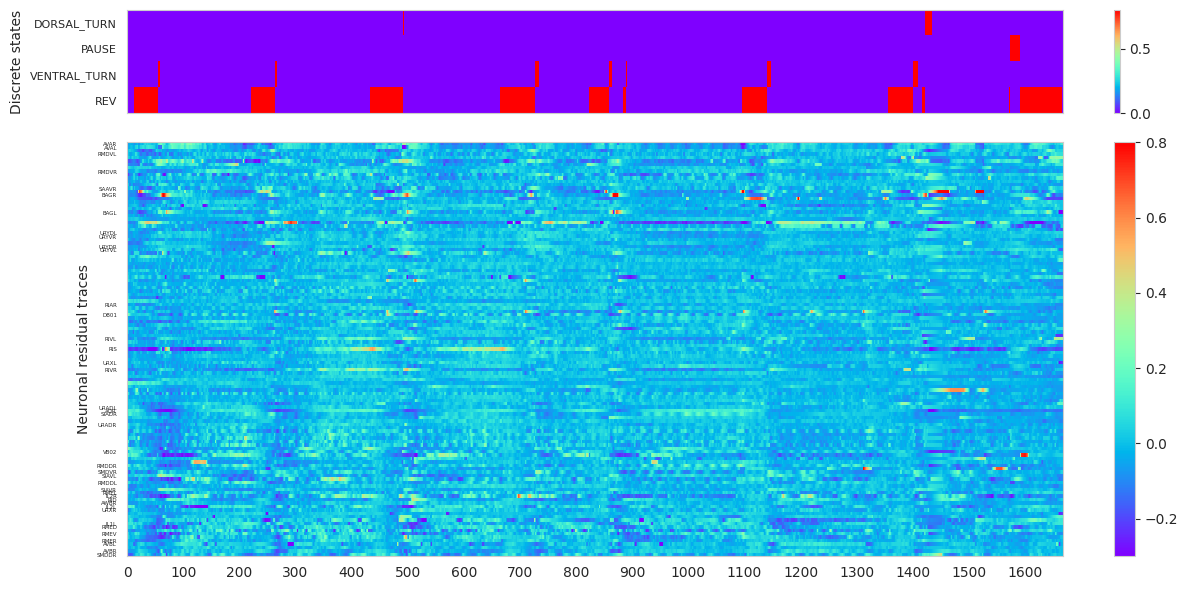

In [12]:
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 4]})

im_top = ax_top.imshow(np.clip(discrete_states[worm_id][selection].values.T[discrete_state_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_top.set_ylabel("Discrete states")
ax_top.set_yticks(np.arange(len(discrete_states[worm_id][selection].values.T)))
ax_top.set_yticklabels(discrete_states[worm_id][selection].columns[discrete_state_indices], fontsize=8)
ax_top.set_xticks(np.arange(0, len(discrete_states[worm_id][selection].values), 100))
fig.colorbar(im_top, ax=ax_top, orientation='vertical', fraction=0.05)
ax_top.grid(False)

im_bottom = ax_bottom.imshow(np.clip(traces_residual[worm_id].values.T[trace_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_bottom.set_ylabel("Neuronal residual traces")
ax_bottom.set_yticks(np.arange(len(traces_residual[worm_id].values.T)))
ax_bottom.set_yticklabels(traces_residual[worm_id].columns[trace_indices], fontsize=4)
ax_bottom.set_xticks(np.arange(0, len(traces_residual[worm_id].values), 100))
fig.colorbar(im_bottom, ax=ax_bottom, orientation='vertical', fraction=0.05)
ax_bottom.grid(False)

plt.tight_layout()
#plt.savefig('./out/traces_residual.png', dpi=300)
plt.show()

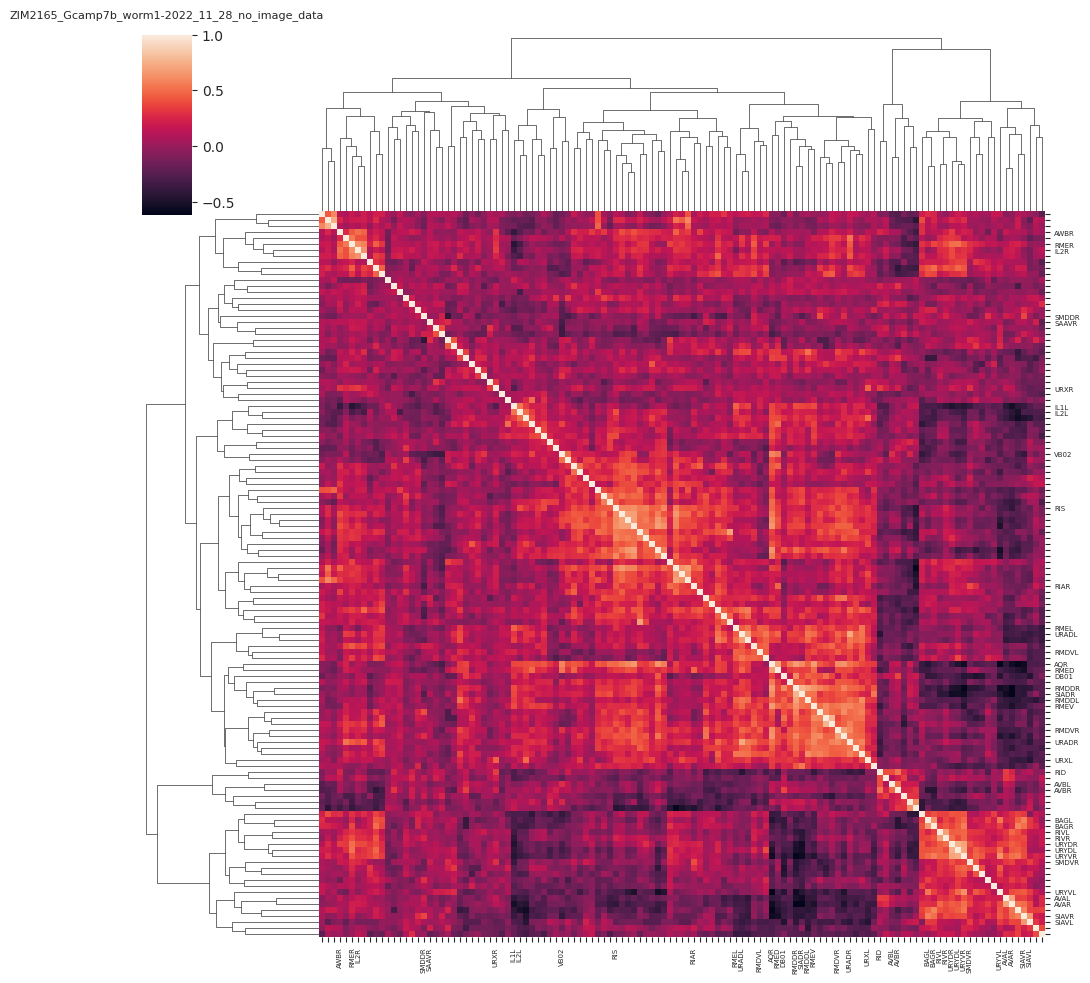

In [13]:
correlation = traces_residual[worm_id].corr()
heatmap = sns.clustermap(correlation, xticklabels=True, yticklabels=True)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(filenames[worm_id], fontsize=8, y=1.05)
pass

0.05863934817977601 0.10336993356152083


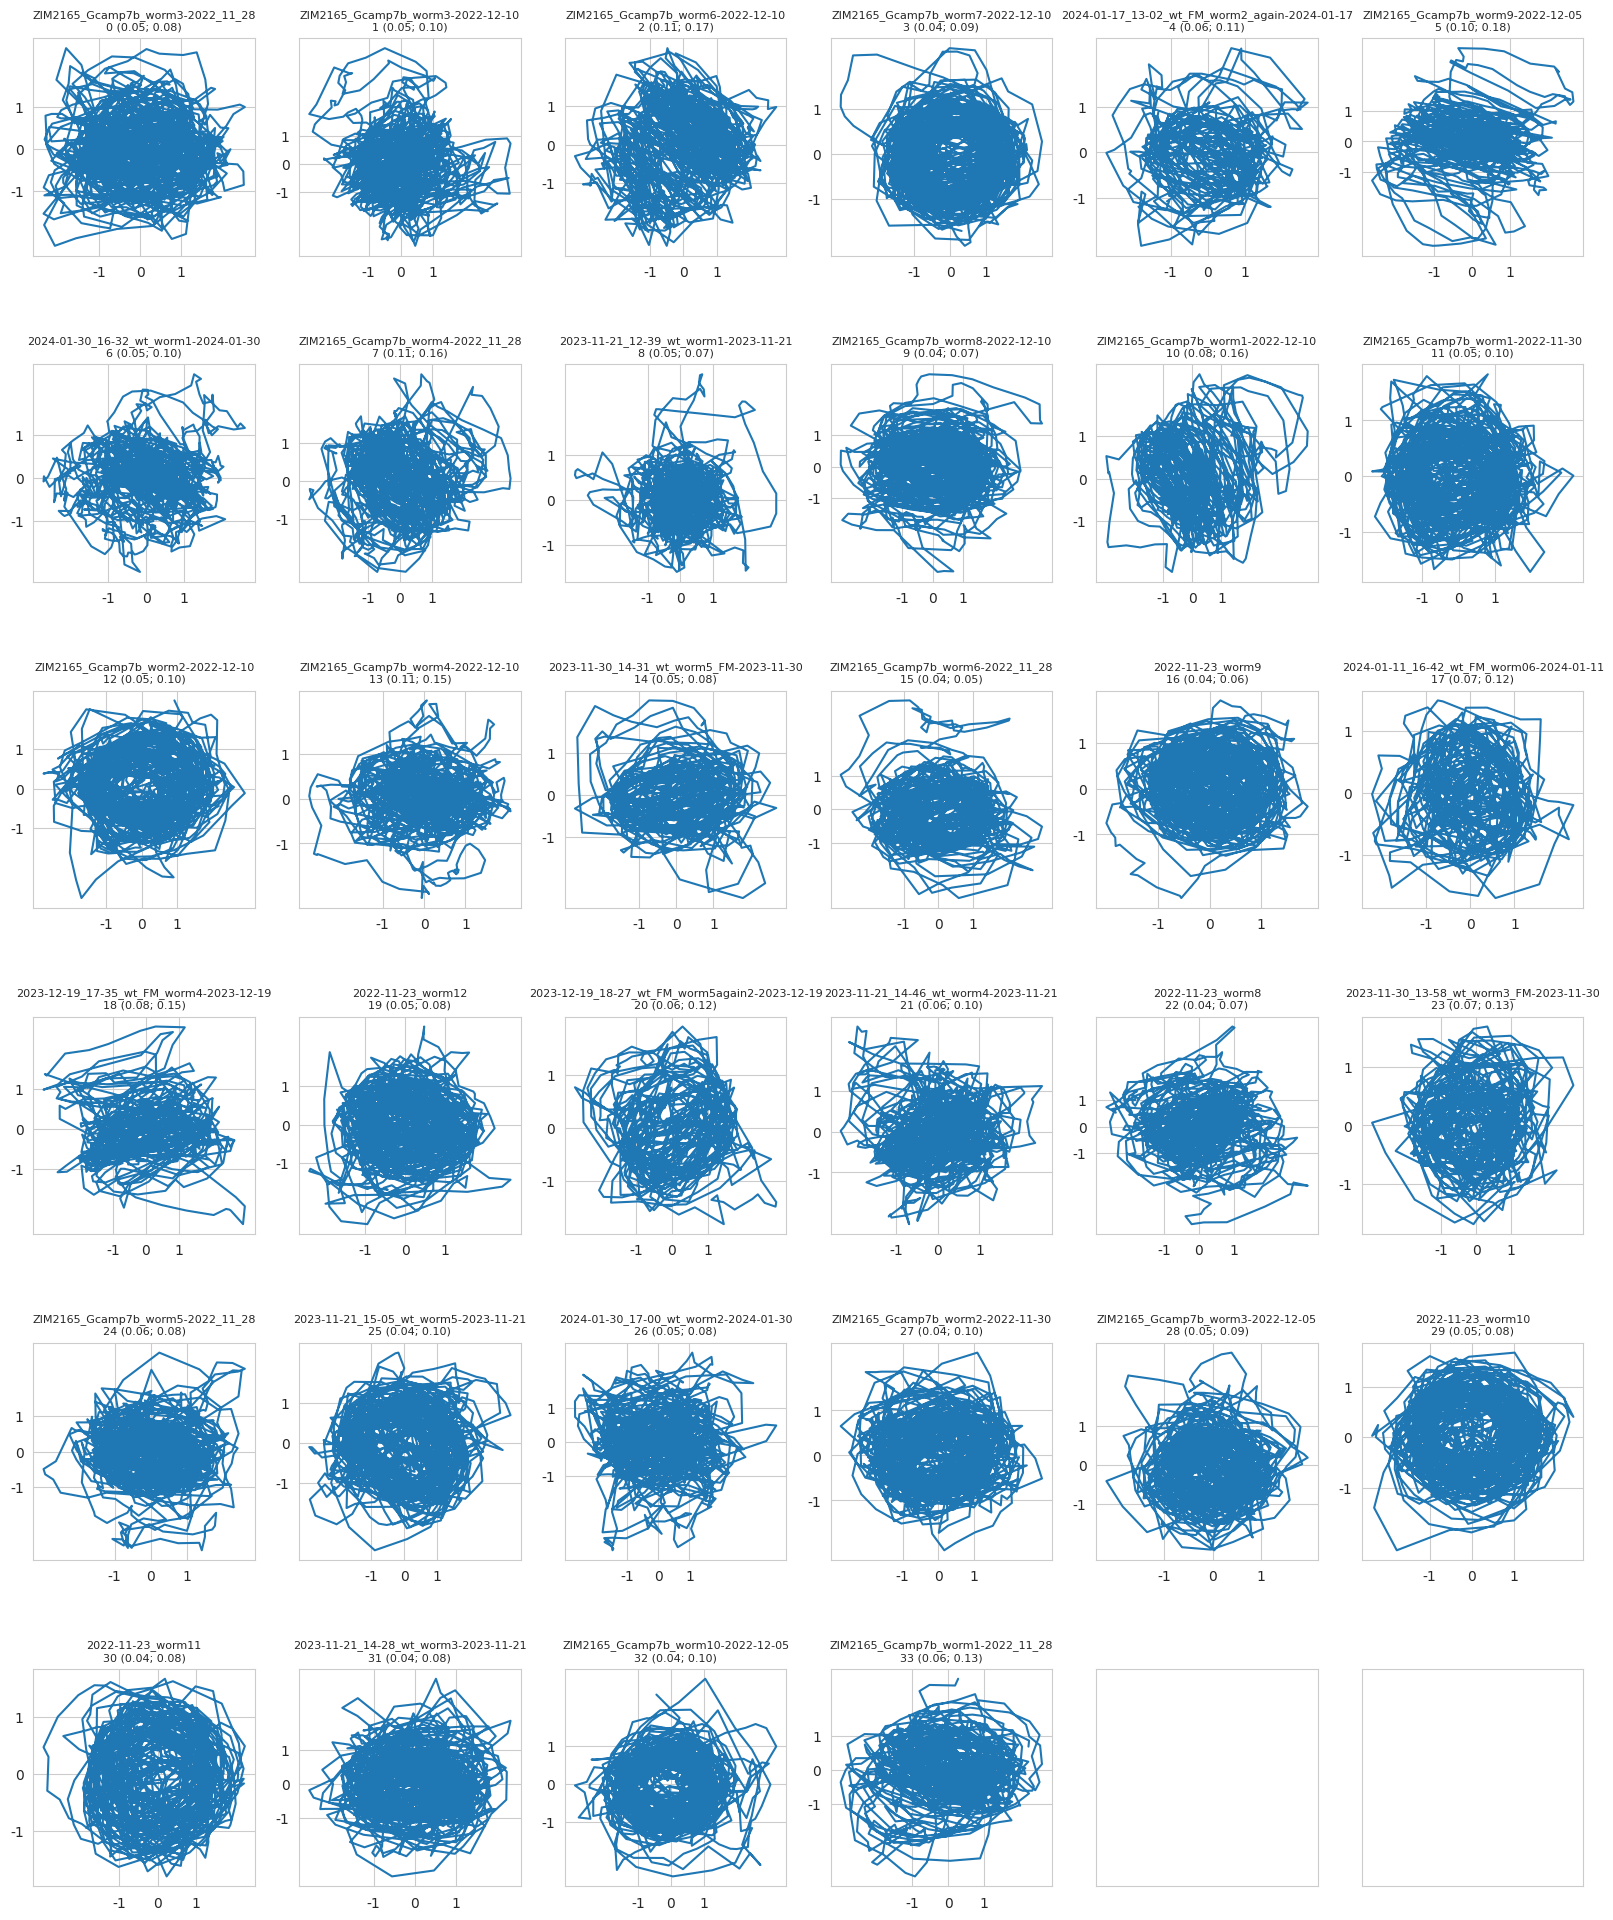

In [14]:
modes_concrete = list()
traces_concrete = list()
cca_con_loadings = list()
con_vars_expl_rs = list()  # variance explained with respect to the manifold-residual data
con_vars_expl = list()
for trace, trace_residual, ew in zip(traces, traces_residual, eigenworms):
	cca = CCA(n_components=5, scale=True)

	trace_residual_reduced, ew_reduced = cca.fit_transform(trace_residual.values, ew.values)
	trace_residual_reconstructed, ew_reconstructed = cca.inverse_transform(trace_residual_reduced, ew_reduced)

	modes_concrete.append(pd.DataFrame(data=trace_residual_reduced, columns=[f'CC{i + 1}' for i in range(5)]))
	traces_concrete.append(pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns))

	cca_con_loadings.append((cca.x_loadings_, cca.y_loadings_))

	X_var_ratio_rs = get_variance_explained(trace_residual, trace_residual_reconstructed)
	X_var_ratio = get_variance_explained(trace, trace_residual_reconstructed)
	con_vars_expl_rs.append(X_var_ratio_rs)
	con_vars_expl.append(X_var_ratio)


n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 24))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

scale = [-1, 0, 1]
for i, mode in enumerate(modes_concrete):
	axes[i // dim, i % dim].plot(mode['CC1'], mode['CC2'])
	axes[i // dim, i % dim].set_xticks(scale)
	axes[i // dim, i % dim].set_xticklabels(scale)
	axes[i // dim, i % dim].set_yticks(scale)
	axes[i // dim, i % dim].set_yticklabels(scale)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n{i} ({con_vars_expl[i]:.2f}; {con_vars_expl_rs[i]:.2f})', fontsize=8)

plt.subplots_adjust(hspace=0.5)
print(np.mean(np.array(con_vars_expl)), np.mean(np.array(con_vars_expl_rs)))

In [15]:
eigenworm_indices = np.argsort(cca_con_loadings[worm_id][1][:, 0])
traces_concrete_indices = np.argsort(cca_con_loadings[worm_id][0][:, 0])

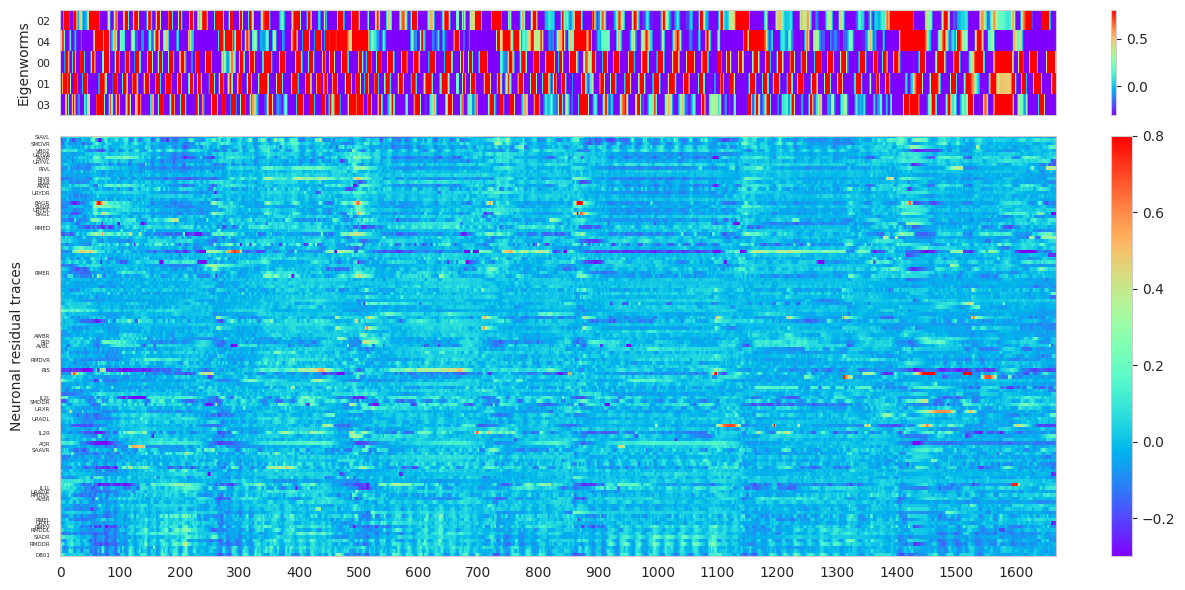

In [19]:
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 4]})

im_top = ax_top.imshow(np.clip(eigenworms[worm_id].values.T[eigenworm_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_top.set_ylabel("Eigenworms")
ax_top.set_yticks(np.arange(len(eigenworms[worm_id].values.T)))
ax_top.set_yticklabels(eigenworms[worm_id].columns[eigenworm_indices], fontsize=8)
ax_top.set_xticks(np.arange(0, len(eigenworms[worm_id].values), 100))
fig.colorbar(im_top, ax=ax_top, orientation='vertical', fraction=0.05)
ax_top.grid(False)

im_bottom = ax_bottom.imshow(np.clip(traces_residual[worm_id].values.T[traces_concrete_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_bottom.set_ylabel("Neuronal residual traces")
ax_bottom.set_yticks(np.arange(len(traces_residual[worm_id].values.T)))
ax_bottom.set_yticklabels(traces_residual[worm_id].columns[traces_concrete_indices], fontsize=4)
ax_bottom.set_xticks(np.arange(0, len(traces_residual[worm_id].values), 100))
fig.colorbar(im_bottom, ax=ax_bottom, orientation='vertical', fraction=0.05)
ax_bottom.grid(False)

plt.tight_layout()
# plt.savefig('./out/traces_manifold_residual.png', dpi=300)
plt.show()

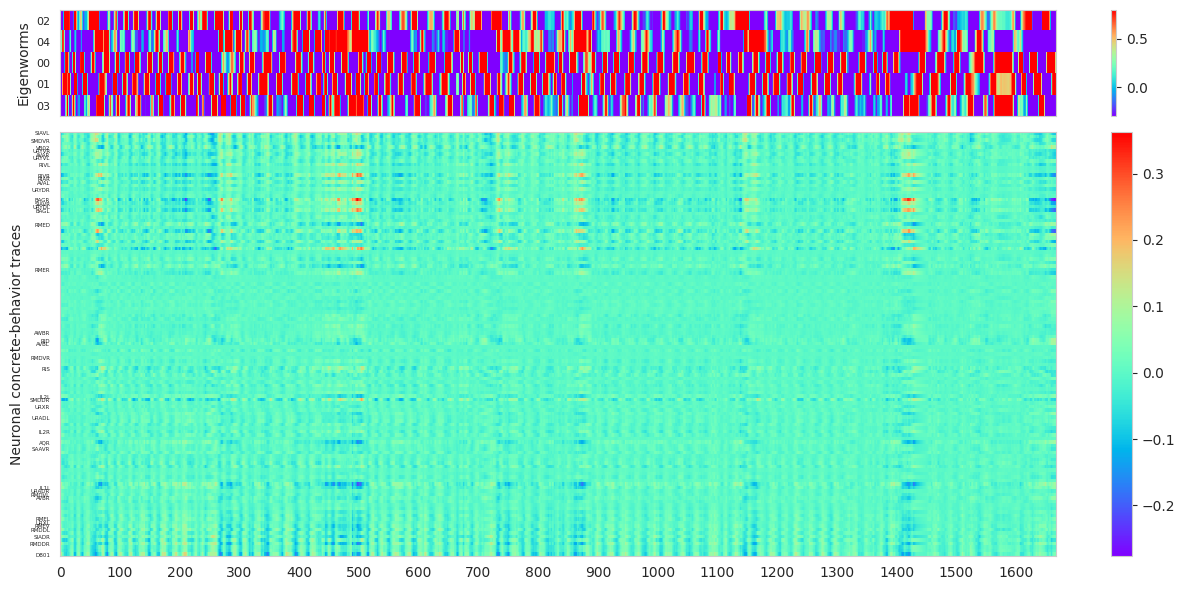

In [20]:
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 4]})

im_top = ax_top.imshow(np.clip(eigenworms[worm_id].values.T[eigenworm_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_top.set_ylabel("Eigenworms")
ax_top.set_yticks(np.arange(len(eigenworms[worm_id].values.T)))
ax_top.set_yticklabels(eigenworms[worm_id].columns[eigenworm_indices], fontsize=8)
ax_top.set_xticks(np.arange(0, len(eigenworms[worm_id].values), 100))
fig.colorbar(im_top, ax=ax_top, orientation='vertical', fraction=0.05)
ax_top.grid(False)

im_bottom = ax_bottom.imshow(np.clip(traces_concrete[worm_id].values.T[traces_concrete_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_bottom.set_ylabel("Neuronal concrete-behavior traces")
ax_bottom.set_yticks(np.arange(len(traces_concrete[worm_id].values.T)))
ax_bottom.set_yticklabels(traces_concrete[worm_id].columns[traces_concrete_indices], fontsize=4)
ax_bottom.set_xticks(np.arange(0, len(traces_concrete[worm_id].values), 100))
fig.colorbar(im_bottom, ax=ax_bottom, orientation='vertical', fraction=0.05)
ax_bottom.grid(False)

plt.tight_layout()
# plt.savefig('./out/traces_concrete-behavior.png', dpi=300)
plt.show()

# other

In [21]:
traces_other = [pd.DataFrame(data=trace_residual.values-trace_concrete.values, columns=trace_residual.columns) for trace_residual, trace_concrete in zip(traces_residual, traces_concrete)]

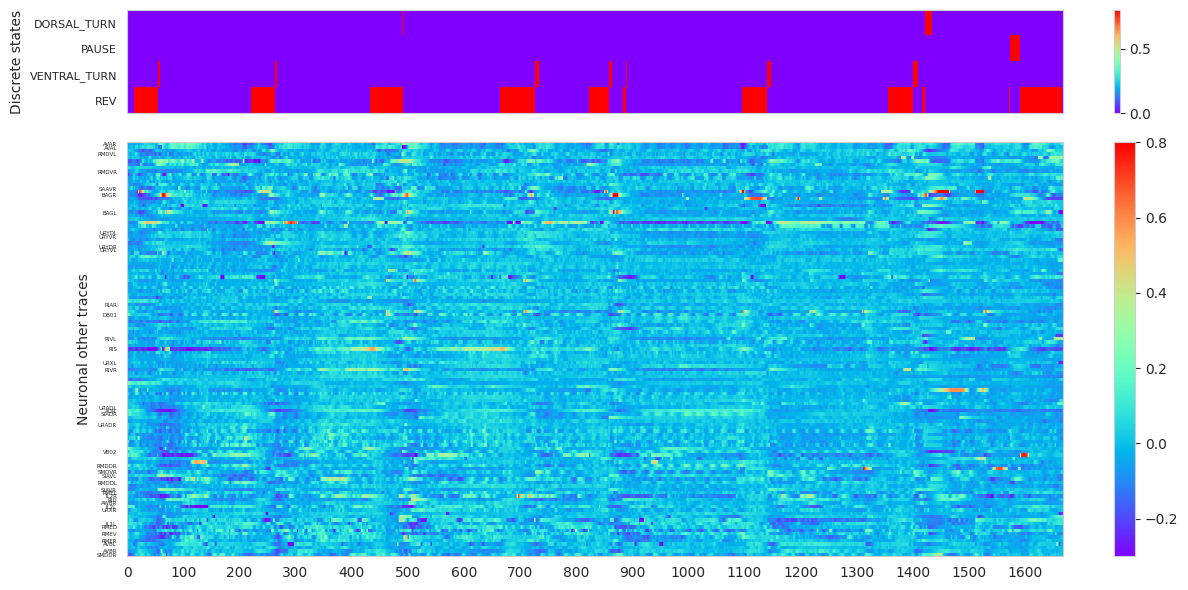

In [22]:
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 4]})

im_top = ax_top.imshow(np.clip(discrete_states[worm_id][selection].values.T[discrete_state_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_top.set_ylabel("Discrete states")
ax_top.set_yticks(np.arange(len(discrete_states[worm_id][selection].values.T)))
ax_top.set_yticklabels(discrete_states[worm_id][selection].columns[discrete_state_indices], fontsize=8)
ax_top.set_xticks(np.arange(0, len(discrete_states[worm_id][selection].values), 100))
fig.colorbar(im_top, ax=ax_top, orientation='vertical', fraction=0.05)
ax_top.grid(False)

im_bottom = ax_bottom.imshow(np.clip(traces_residual[worm_id].values.T[trace_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_bottom.set_ylabel("Neuronal other traces")
ax_bottom.set_yticks(np.arange(len(traces_residual[worm_id].values.T)))
ax_bottom.set_yticklabels(traces_residual[worm_id].columns[trace_indices], fontsize=4)
ax_bottom.set_xticks(np.arange(0, len(traces_residual[worm_id].values), 100))
fig.colorbar(im_bottom, ax=ax_bottom, orientation='vertical', fraction=0.05)
ax_bottom.grid(False)

plt.tight_layout()
# plt.savefig('./out/traces_other.png', dpi=300)
plt.show()

# total reconstruction error

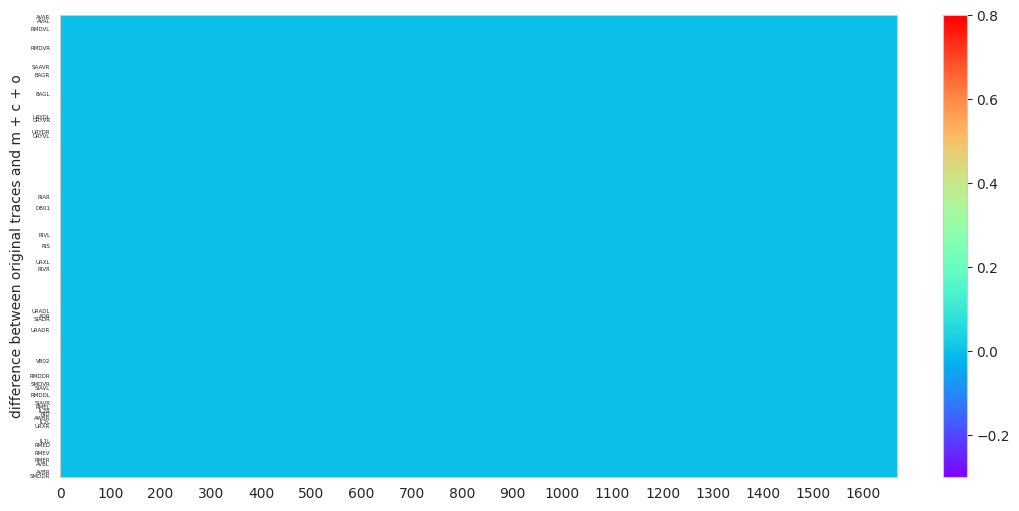

In [23]:
trace_diff = pd.DataFrame(data=traces[worm_id].values - (traces_manifold[worm_id].values + traces_concrete[worm_id].values + traces_other[worm_id].values), columns=traces[worm_id].columns)

plt.figure(figsize=(12, 6))

plt.imshow(trace_diff.values.T[trace_indices], aspect='auto', cmap='rainbow', interpolation='nearest', norm=colors.Normalize(vmin=-0.3, vmax=0.8))
plt.ylabel("difference between original traces and m + c + o")
plt.yticks(np.arange(len(trace_diff.values.T)), labels=trace_diff.columns[trace_indices], fontsize=4)
plt.xticks(np.arange(0, len(trace_diff.values), 100))
plt.colorbar(orientation='vertical', fraction=0.05)
plt.grid(False)

# variance ratios per neuron per dataset

In [31]:
mcos = list()
mco_ratios = list()
for i in range(len(filenames)):

	traces_all_var = np.var(traces[i].values, axis=0)
	traces_res_var = np.var(traces_residual[i].values, axis=0)
	traces_man_var = traces_all_var - traces_res_var
	traces_oth_var = np.var(traces_other[i].values, axis=0)
	traces_con_var = traces_res_var - traces_oth_var
	mco = pd.DataFrame(data=np.vstack([traces_all_var, traces_man_var, traces_res_var, traces_con_var, traces_oth_var]),
					   columns=traces[i].columns,
					   index=['a', 'm', 'r', 'c', 'o'])
	mcos.append(mco)

	traces_all_var_ratio = traces_all_var / traces_all_var
	traces_res_var_ratio = traces_res_var / traces_all_var
	traces_man_var_ratio = traces_man_var / traces_all_var
	traces_oth_var_ratio = traces_oth_var / traces_all_var
	traces_con_var_ratio = traces_con_var / traces_all_var
	mco_ratio = pd.DataFrame(data=np.vstack([traces_all_var_ratio, traces_man_var_ratio, traces_res_var_ratio, traces_con_var_ratio, traces_oth_var_ratio]),
							 columns=traces[i].columns,
							 index=['a', 'm', 'r', 'c', 'o'])
	mco_ratios.append(mco_ratio)


neurons_labels = [traces[i].columns for i in range(len(filenames))]
unique_labels = sorted(list(set([l for label in neurons_labels for l in label])))
unique_labels_filtered = [label for label in unique_labels if label != '']

mcos_filtered = list()
for mco in mcos:
	mco_filtered = mco.loc[:, [column for column in mco.columns if column in unique_labels_filtered]]
	if len(mco_filtered.columns) > 0:
		mcos_filtered.append(mco_filtered)
mco_ratios_filtered = list()
for mco_ratio in mco_ratios:
	mco_ratio_filtered = mco_ratio.loc[:, [column for column in mco_ratio.columns if column in unique_labels_filtered]]
	if len(mco_ratio_filtered.columns) > 0:
		mco_ratios_filtered.append(mco_ratio_filtered)

# total variance ratios

In [32]:
# variance ratio per neuron, averaged across one pool containing all datasets
mco_ratios_average = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels_filtered)
mco_ratios_stddev = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels_filtered)
for neuron in unique_labels_filtered:
	amrco = {'a': [], 'm': [], 'r': [], 'c': [], 'o': []}
	for mco_ratio in mco_ratios_filtered:
		if neuron in mco_ratio.columns:
			for key in amrco.keys():
				amrco[key].append(mco_ratio[neuron][key])
	mco_ratios_average[neuron] = [np.mean(np.array(amrco[key])) for key in amrco.keys()]
	mco_ratios_stddev[neuron] = [np.std(np.array(amrco[key])) for key in amrco.keys()]

mco_ratios_averages = {
	'a': -1,
	'r': -1,
	'm': np.mean(np.array(man_vars_expl)),
	'c': np.mean(np.array(con_vars_expl)),
	'o': 1 - np.mean(np.array(man_vars_expl)) - np.mean(np.array(con_vars_expl))}

# M-C-O plots

/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


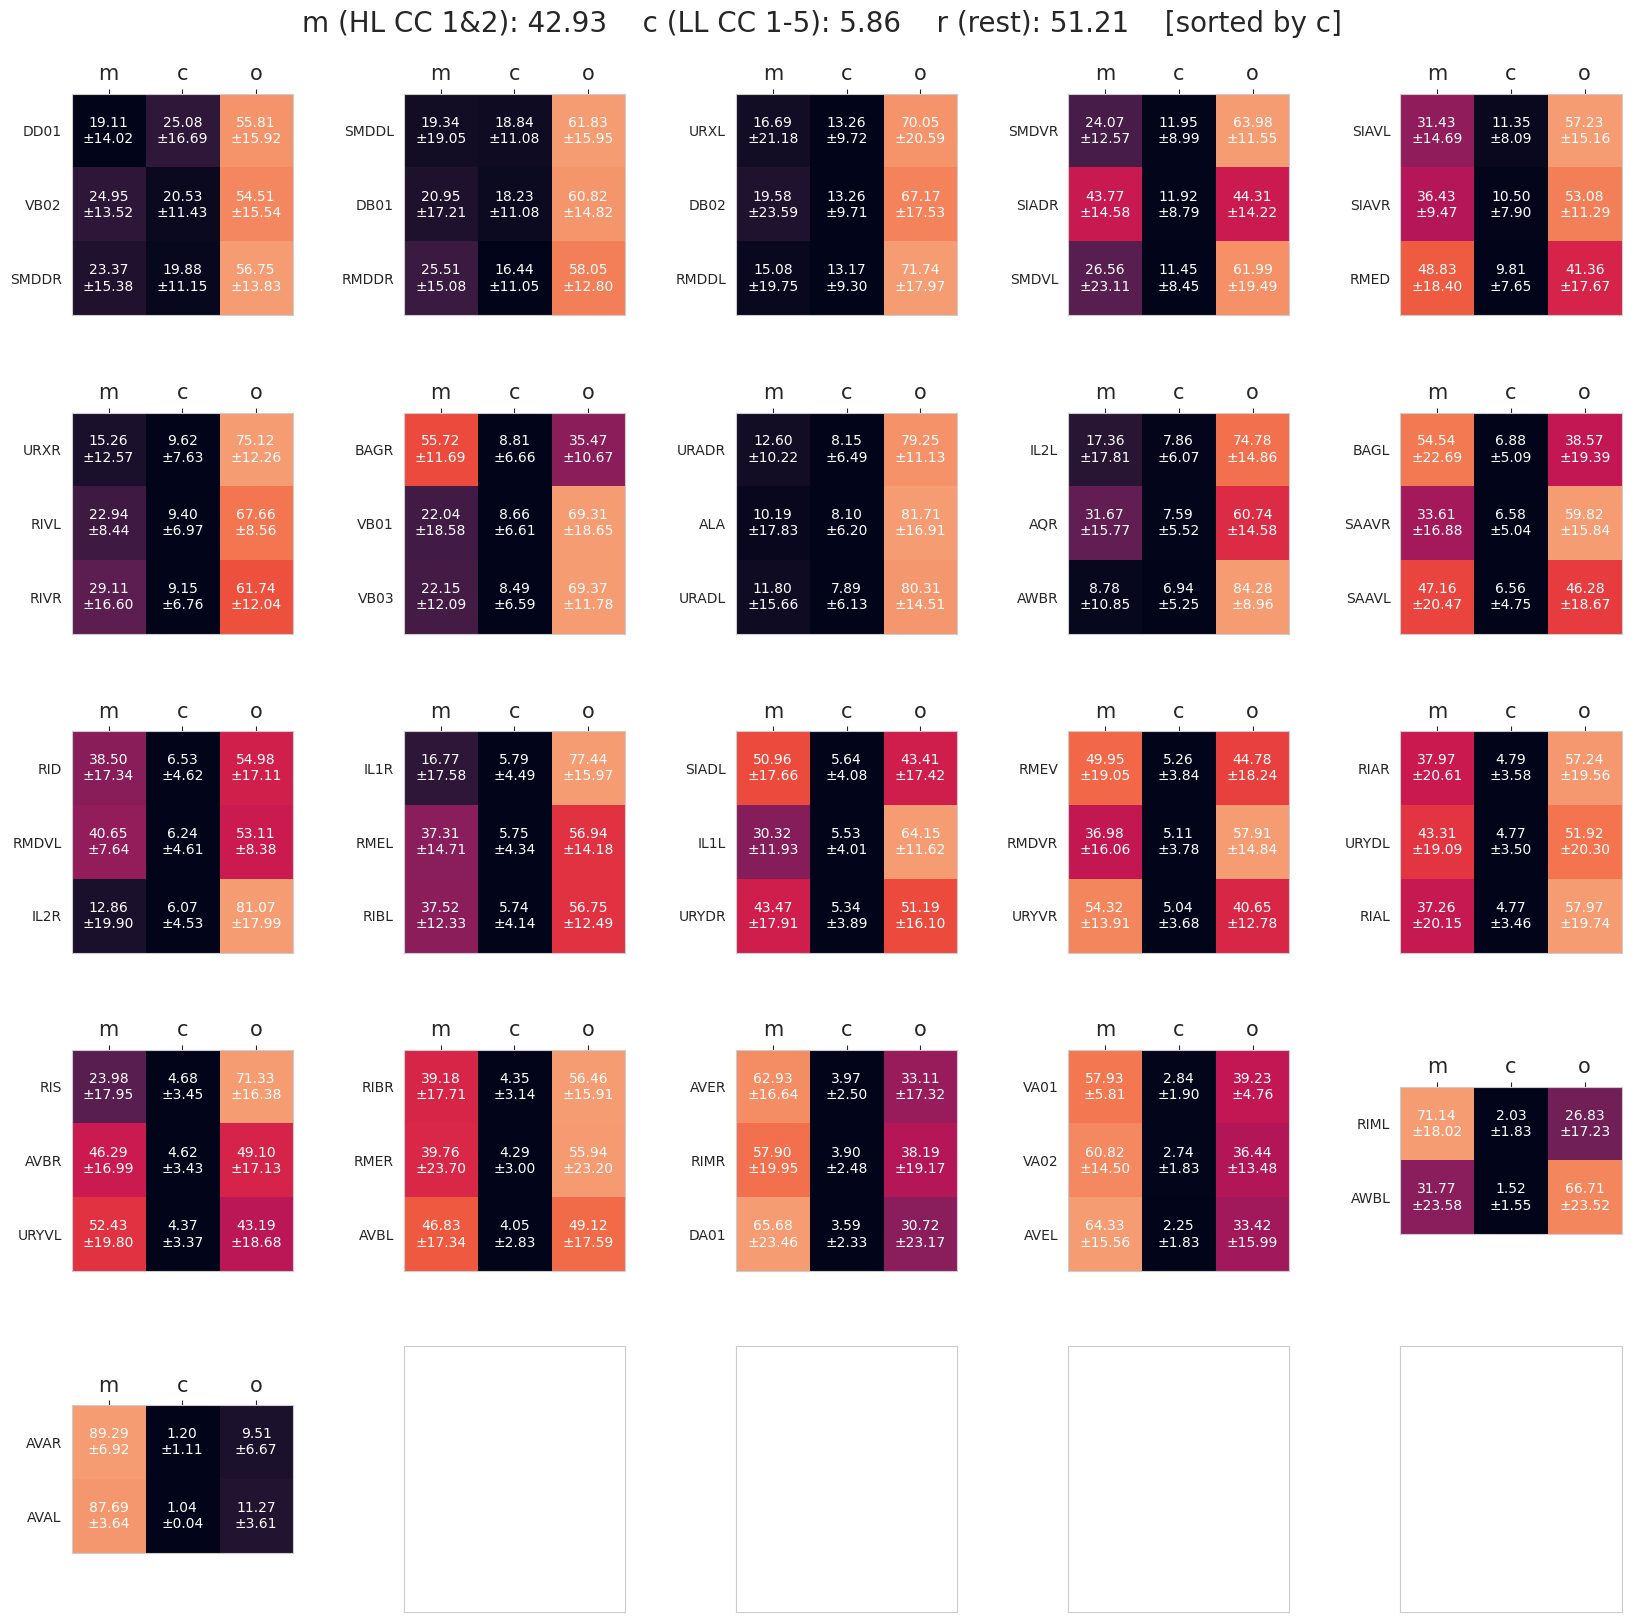

In [33]:
mco_avg = mco_ratios_average.T[['m', 'c', 'o']].sort_values(by='c', ascending=False).T
mco_std = mco_ratios_stddev.T[['m', 'c', 'o']].sort_values(by='c', ascending=False).T

mco_avg_split = np.array_split(mco_avg.T, math.ceil(len(mco_avg.columns) / 3))
mco_std_split = np.array_split(mco_std.T, math.ceil(len(mco_std.columns) / 3))

n_plots = 25
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 20))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)
plt.subplots_adjust(wspace=0.5)

cmap = colors.LinearSegmentedColormap.from_list(
    'rocket_d', plt.get_cmap('rocket')(np.linspace(0.0, 0.8, 256))
)
for i, (avg_df, std_df) in enumerate(zip(mco_avg_split, mco_std_split)):
	img = axes[i // dim, i % dim].imshow(avg_df.values, cmap=cmap)
	for j in range(avg_df.shape[0]):
		for k in range(avg_df.shape[1]):
			axes[i // dim, i % dim].text(k, j, f'{avg_df.iloc[j, k] * 100:.2f}\n±{std_df.iloc[j, k] * 100:.2f}', ha='center', va='center', color='w')
	axes[i // dim, i % dim].set_xticks(np.arange(avg_df.shape[1]), avg_df.columns, fontsize=15)
	axes[i // dim, i % dim].set_yticks(np.arange(avg_df.shape[0]), avg_df.index, fontsize=10)
	axes[i // dim, i % dim].xaxis.set_ticks_position('top')
	axes[i // dim, i % dim].xaxis.set_label_position('top')
	#fig.colorbar(img, ax=axes[i // dim, i % dim], orientation='vertical', fraction=0.05)

fig.text(0.5, 0.9, f'm (HL CC 1&2): {mco_ratios_averages['m'] * 100:.2f}    c (LL CC 1-5): {mco_ratios_averages['c'] * 100:.2f}    r (rest): {mco_ratios_averages['o'] * 100:.2f}    [sorted by c]', ha='center', fontsize=20)

# fig.savefig('./out/mro_ratios-c', dpi=300)
pass

/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


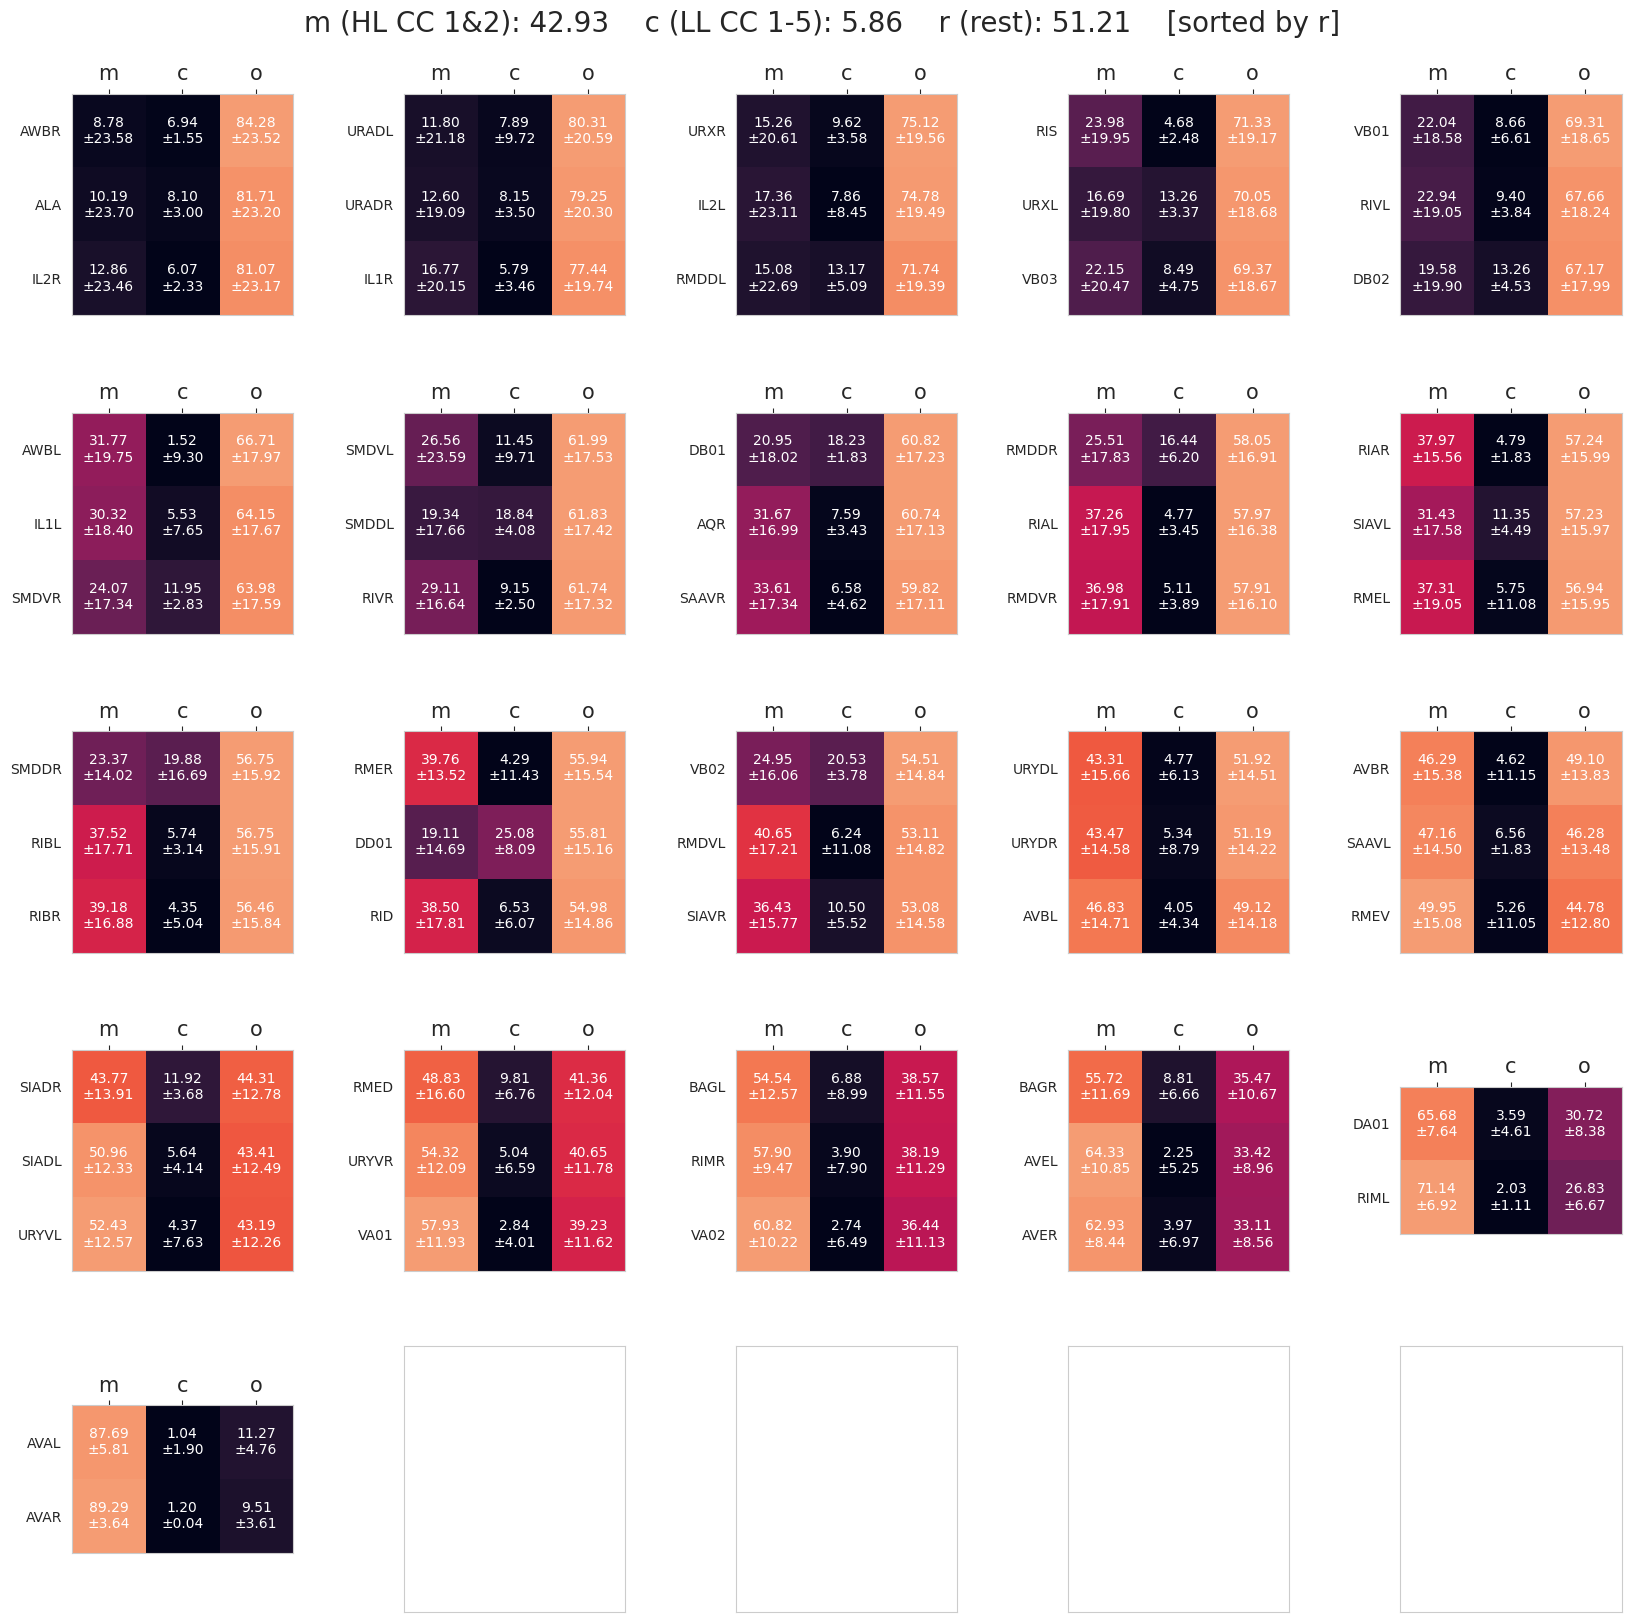

In [34]:
mco_avg = mco_ratios_average.T[['m', 'c', 'o']].sort_values(by='o', ascending=False).T
mco_std = mco_ratios_stddev.T[['m', 'c', 'o']].sort_values(by='o', ascending=False).T

mco_avg_split = np.array_split(mco_avg.T, math.ceil(len(mco_avg.columns) / 3))
mco_std_split = np.array_split(mco_std.T, math.ceil(len(mco_std.columns) / 3))

n_plots = 25
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 20))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)
plt.subplots_adjust(wspace=0.5)

cmap = colors.LinearSegmentedColormap.from_list(
    'rocket_d', plt.get_cmap('rocket')(np.linspace(0.0, 0.8, 256))
)
for i, (avg_df, std_df) in enumerate(zip(mco_avg_split, mco_std_split)):
	img = axes[i // dim, i % dim].imshow(avg_df.values, cmap=cmap)
	for j in range(avg_df.shape[0]):
		for k in range(avg_df.shape[1]):
			axes[i // dim, i % dim].text(k, j, f'{avg_df.iloc[j, k] * 100:.2f}\n±{std_df.iloc[j, k] * 100:.2f}', ha='center', va='center', color='w')
	axes[i // dim, i % dim].set_xticks(np.arange(avg_df.shape[1]), avg_df.columns, fontsize=15)
	axes[i // dim, i % dim].set_yticks(np.arange(avg_df.shape[0]), avg_df.index, fontsize=10)
	axes[i // dim, i % dim].xaxis.set_ticks_position('top')
	axes[i // dim, i % dim].xaxis.set_label_position('top')
	#fig.colorbar(img, ax=axes[i // dim, i % dim], orientation='vertical', fraction=0.05)

fig.text(0.5, 0.9, f'm (HL CC 1&2): {mco_ratios_averages['m'] * 100:.2f}    c (LL CC 1-5): {mco_ratios_averages['c'] * 100:.2f}    r (rest): {mco_ratios_averages['o'] * 100:.2f}    [sorted by r]', ha='center', fontsize=20)

# fig.savefig('./out/mro_ratios-r', dpi=300)
pass

/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


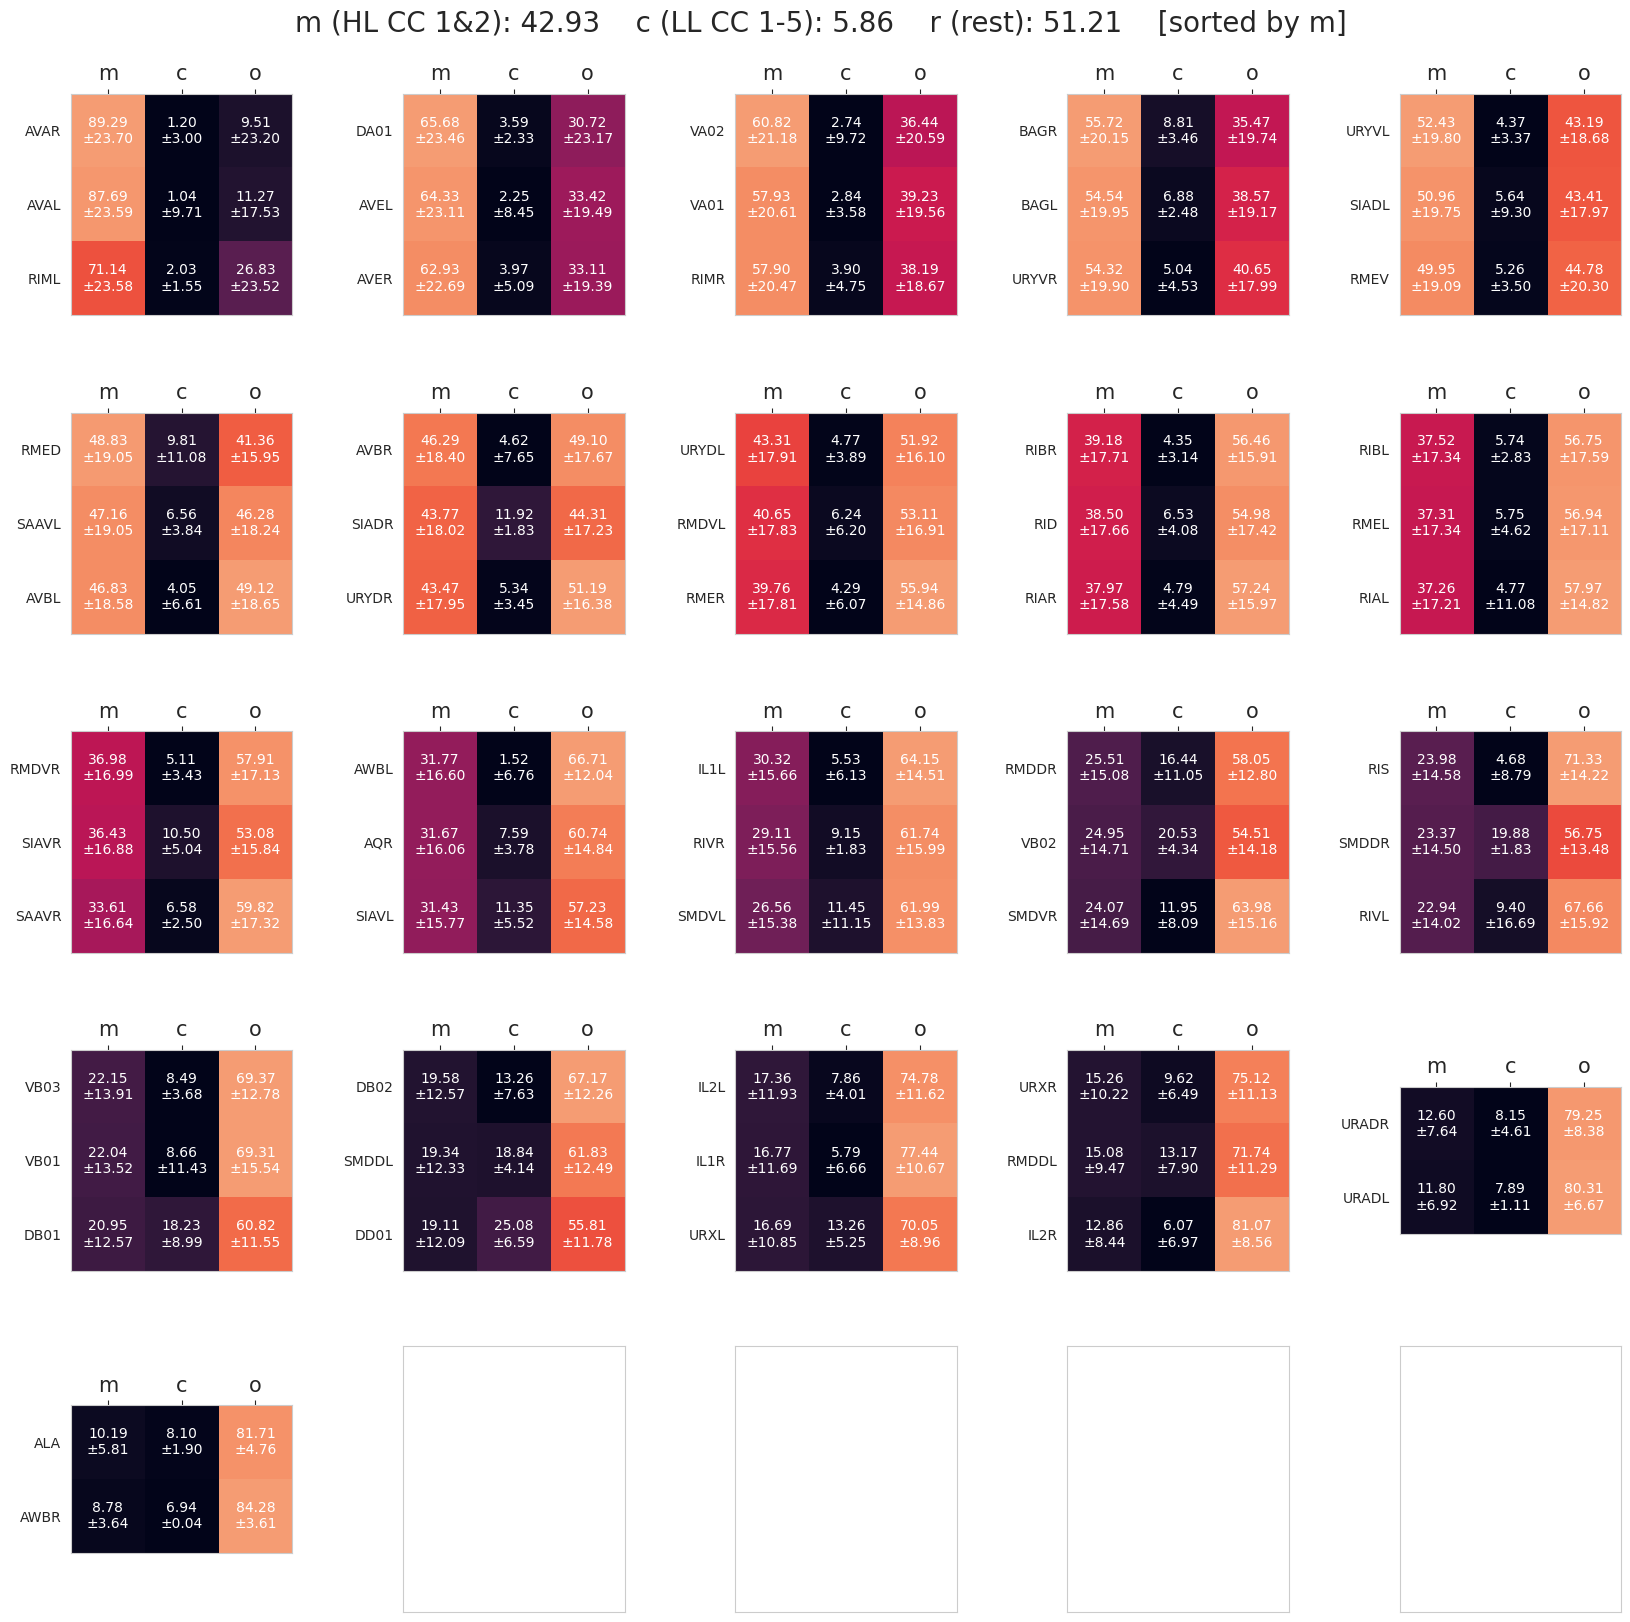

In [35]:
mco_avg = mco_ratios_average.T[['m', 'c', 'o']].sort_values(by='m', ascending=False).T
mco_std = mco_ratios_stddev.T[['m', 'c', 'o']].sort_values(by='m', ascending=False).T

mco_avg_split = np.array_split(mco_avg.T, math.ceil(len(mco_avg.columns) / 3))
mco_std_split = np.array_split(mco_std.T, math.ceil(len(mco_std.columns) / 3))

n_plots = 25
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 20))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)
plt.subplots_adjust(wspace=0.5)

cmap = colors.LinearSegmentedColormap.from_list(
    'rocket_d', plt.get_cmap('rocket')(np.linspace(0.0, 0.8, 256))
)
for i, (avg_df, std_df) in enumerate(zip(mco_avg_split, mco_std_split)):
	img = axes[i // dim, i % dim].imshow(avg_df.values, cmap=cmap)
	for j in range(avg_df.shape[0]):
		for k in range(avg_df.shape[1]):
			axes[i // dim, i % dim].text(k, j, f'{avg_df.iloc[j, k] * 100:.2f}\n±{std_df.iloc[j, k] * 100:.2f}', ha='center', va='center', color='w')
	axes[i // dim, i % dim].set_xticks(np.arange(avg_df.shape[1]), avg_df.columns, fontsize=15)
	axes[i // dim, i % dim].set_yticks(np.arange(avg_df.shape[0]), avg_df.index, fontsize=10)
	axes[i // dim, i % dim].xaxis.set_ticks_position('top')
	axes[i // dim, i % dim].xaxis.set_label_position('top')
	#fig.colorbar(img, ax=axes[i // dim, i % dim], orientation='vertical', fraction=0.05)

fig.text(0.5, 0.9, f'm (HL CC 1&2): {mco_ratios_averages['m'] * 100:.2f}    c (LL CC 1-5): {mco_ratios_averages['c'] * 100:.2f}    r (rest): {mco_ratios_averages['o'] * 100:.2f}    [sorted by m]', ha='center', fontsize=20)

# fig.savefig('./out/mro_ratios-m', dpi=300)
pass